In [ ]:
# @title
# Cell 1: Import necessary libraries and load the dataset
import pandas as pd
import numpy as np

# Set random seeds for reproducibility
np.random.seed(42)
import tensorflow as tf
tf.random.set_seed(42)

# Load the dataset
df = pd.read_csv('ai4i2020.csv')

print("Dataset loaded successfully.")

Dataset loaded successfully.


## 1. Dataset Inspection

As requested, let's inspect the dataset to understand its structure, columns, and data types. This will inform our feature selection and preprocessing steps.

In [ ]:
# @title
# Cell 2: Display the first 5 rows of the dataset
display(df.head())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
# @title
# Cell 3: Display basic information about the dataset, including data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
# @title
# Cell 4: Display descriptive statistics for numerical columns
display(df.describe())

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


## 2. Feature Selection and Target Definition

Based on the project requirements, we will define the target and select predictive features. We need to be careful about identifiers and potential data leakage.

In [ ]:
# @title
# Cell 5: Define target and select features

# Target variable
TARGET = 'Machine failure'
y = df[TARGET]

# Exclude identifier columns as they do not provide predictive information
# Exclude failure mode indicators to prevent data leakage, as they are direct labels of failure causes
# rather than independent predictors of impending failure. Using them would mean predicting failure
# with information that essentially *is* failure or its immediate aftermath.
EXCLUDE_COLS = ['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Selected features
features = [col for col in df.columns if col not in EXCLUDE_COLS]
X = df[features]

print(f"Target variable: '{TARGET}'")
print(f"Selected features: {features}")
print(f"Shape of X: {X.shape}")
print(f"Shape of y: {y.shape}")

Target variable: 'Machine failure'
Selected features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
Shape of X: (10000, 6)
Shape of y: (10000,)


## 3. Preprocessing: Handling Categorical Features and Train-Test Split

We will now one-hot encode the categorical 'Type' feature and then split the data into training and testing sets. Given the imbalance in the target variable, a stratified split is crucial for reproducibility and fair evaluation.

In [ ]:
# @title
# Cell 6: One-hot encode categorical features and perform train-test split
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# One-hot encode the 'Type' categorical feature
X_encoded = pd.get_dummies(X, columns=['Type'], drop_first=True)

# Perform stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2, # 20% for testing
    random_state=42, # for reproducibility
    stratify=y # essential for imbalanced datasets
)

print("Categorical features encoded.")
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Display the first few rows of the encoded training data to confirm
print("\nFirst 5 rows of X_train (encoded):")
display(X_train.head())

Categorical features encoded.
Shape of X_train: (8000, 7)
Shape of X_test: (2000, 7)
Shape of y_train: (8000,)
Shape of y_test: (2000,)

First 5 rows of X_train (encoded):


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_L,Type_M
4058,302.0,310.9,1456,47.2,54,False,True
1221,297.0,308.3,1399,46.4,132,False,True
6895,301.0,311.6,1357,45.6,137,False,True
9863,298.9,309.8,1411,56.3,84,True,False
8711,297.1,308.5,1733,28.7,50,True,False


## 4. Preprocessing for CNN: Scaling and Reshaping

For the CNN, numerical features need to be scaled. It's critical to fit the scaler only on the training data to prevent data leakage. Finally, the data will be reshaped into the `(samples, features, 1)` format required by `Conv1D` layers.

In [ ]:
# @title
# Cell 7: Scale numerical features and reshape for Conv1D

# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training data and transform both training and test data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reshape data for Conv1D: (samples, timesteps, features)
# Here, 'timesteps' is 1 (each feature is a 'timestep' in its own right for this tabular data interpretation)
# and 'features' is effectively 1 (as each feature is treated as a single input channel).
# Or more commonly for tabular data, (samples, features, 1)
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

print("Features scaled and reshaped for Conv1D.")
print(f"Shape of X_train_cnn: {X_train_cnn.shape}")
print(f"Shape of X_test_cnn: {X_test_cnn.shape}")

Features scaled and reshaped for Conv1D.
Shape of X_train_cnn: (8000, 7, 1)
Shape of X_test_cnn: (2000, 7, 1)


## 5. Handle Class Imbalance

Machine failure datasets are typically imbalanced. We will inspect the target distribution and use class weights to mitigate this imbalance during model training.

/tmp/ipykernel_2100/3459571650.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette='viridis')


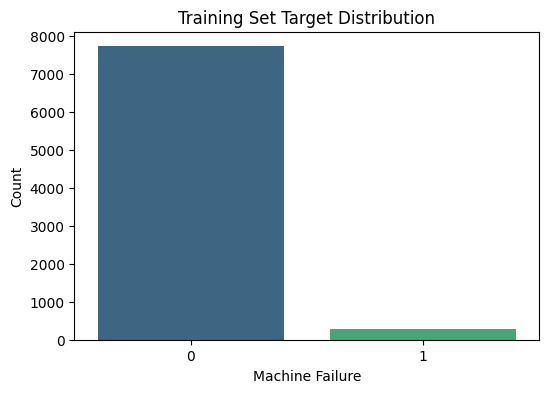

Number of non-failures in training set: 7729
Number of failures in training set: 271
Failure percentage in training set: 3.39%
Calculated class weights: {0: np.float64(0.51753137533963), 1: np.float64(14.760147601476016)}


In [ ]:
# @title
# Cell 8: Analyze target distribution and calculate class weights
from sklearn.utils import class_weight
import matplotlib.pyplot as plt
import seaborn as sns

# Plot class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, palette='viridis')
plt.title('Training Set Target Distribution')
plt.xlabel('Machine Failure')
plt.ylabel('Count')
plt.show()

# Report class counts and percentage
failure_count = y_train.sum()
non_failure_count = len(y_train) - failure_count
total_samples = len(y_train)
failure_percentage = (failure_count / total_samples) * 100

print(f"Number of non-failures in training set: {non_failure_count}")
print(f"Number of failures in training set: {failure_count}")
print(f"Failure percentage in training set: {failure_percentage:.2f}%")

# Calculate class weights for imbalanced dataset
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights_dict = dict(enumerate(class_weights))

print(f"Calculated class weights: {class_weights_dict}")

## 6. Build the 1D CNN Model (Task 7)

We will now construct the 1D CNN architecture as specified, using Keras/TensorFlow. The architecture will include Conv1D layers, ReLU activations, Batch Normalization, MaxPooling, Global Average Pooling, Dense layers, Dropout, and a Sigmoid output for binary classification.

In [ ]:
# @title
# Cell 9: Build the 1D CNN model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalAveragePooling1D, Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam

# Determine the number of features after encoding and scaling
num_features = X_train_cnn.shape[1]

# Define the CNN model
model = Sequential([
    Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(num_features, 1), name='conv1d_1'),
    BatchNormalization(name='batch_norm_1'),
    MaxPooling1D(pool_size=2, name='max_pooling_1'),
    Conv1D(filters=64, kernel_size=2, activation='relu', name='conv1d_2'), # Changed kernel_size from 3 to 2
    BatchNormalization(name='batch_norm_2'),
    GlobalAveragePooling1D(name='global_avg_pooling'), # Use GlobalAveragePooling to reduce dimensionality
    Dense(64, activation='relu', name='dense_1'),
    Dropout(0.5, name='dropout_1'), # Dropout for regularization
    Dense(1, activation='sigmoid', name='output_layer') # Sigmoid for binary classification
])

# Compile the model
# Using Adam optimizer with a slightly reduced learning rate for stability
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall(), tf.keras.metrics.AUC()])

# Display model summary
model.summary()

print("1D CNN model built and compiled.")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 5, 32)          │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 5, 32)          │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling_1 (MaxPooling1D)    │ (None, 2, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 1, 64)          │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 1, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pooling              │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,897 (34.75 KB)

 Trainable params: 8,705 (34.00 KB)

 Non-trainable params: 192 (768.00 B)

1D CNN model built and compiled.


In [ ]:
# @title
# Cell 10: Train the CNN model (re-run after fixing architecture)
from tensorflow.keras.callbacks import EarlyStopping

# Define Early Stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss', # Monitor validation loss
    patience=10,        # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True # Restore model weights from the epoch with the best value of the monitored quantity
)

# Train the model
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=100, # Increased epochs but early stopping will manage actual training duration
    batch_size=32,
    validation_split=0.2, # Create a validation set from the training data
    class_weight=class_weights_dict, # Apply class weights
    callbacks=[early_stopping],
    verbose=1
)

print("CNN model training complete.")

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7713 - auc: 0.8570 - loss: 0.4803 - precision: 0.1100 - recall: 0.8148 - val_accuracy: 0.9463 - val_auc: 0.9092 - val_loss: 0.3160 - val_precision: 0.3333 - val_recall: 0.5636
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8222 - auc: 0.9244 - loss: 0.3497 - precision: 0.1454 - recall: 0.8750 - val_accuracy: 0.9237 - val_auc: 0.9428 - val_loss: 0.2145 - val_precision: 0.2810 - val_recall: 0.7818
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8584 - auc: 0.9410 - loss: 0.3089 - precision: 0.1823 - recall: 0.9167 - val_accuracy: 0.8913 - val_auc: 0.9496 - val_loss: 0.2659 - val_precision: 0.2308 - val_recall: 0.9273
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8573 - auc: 0.9421 - loss: 0.3045 - precision: 0.1794 - recall: 0.9028 - val_accuracy: 0.9056 - val_auc: 0.9514 - val_loss: 0.2281 - val_precision: 0.2551 - val_recall: 0.9091
Epoch 5/100
200/200 ━━━━━━━━

## 8. Training History Visualization (Re-run)

Visualizing the training and validation loss and accuracy helps in understanding the model's learning process and detecting overfitting or underfitting.

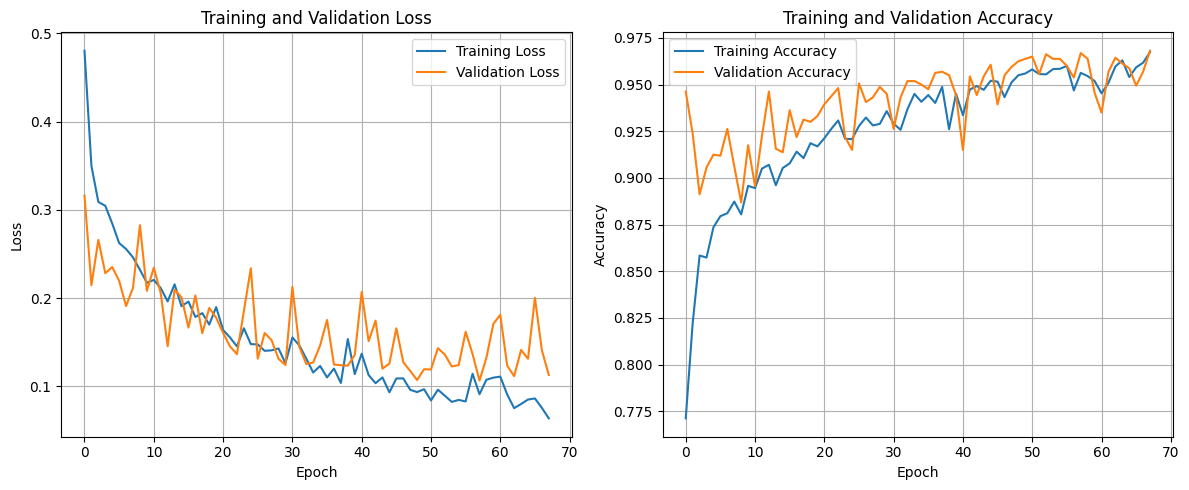

Training history plots generated.


In [ ]:
# @title
# Cell 11: Plot training and validation loss/accuracy (re-run)
import matplotlib.pyplot as plt

hist_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 5))

# Plot 1: Training vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(hist_df['loss'], label='Training Loss')
plt.plot(hist_df['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Training vs Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(hist_df['accuracy'], label='Training Accuracy')
plt.plot(hist_df['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Training history plots generated.")

## 9. Evaluate the CNN Model on Test Set (Task 7 - Re-run)

Now, we will evaluate the trained CNN model on the untouched test set using various metrics suitable for imbalanced classification problems.

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

--- CNN Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.49      0.66      0.57        68

    accuracy                           0.97      2000
   macro avg       0.74      0.82      0.77      2000
weighted avg       0.97      0.97      0.97      2000


--- CNN Confusion Matrix ---
[[1886   46]
 [  23   45]]


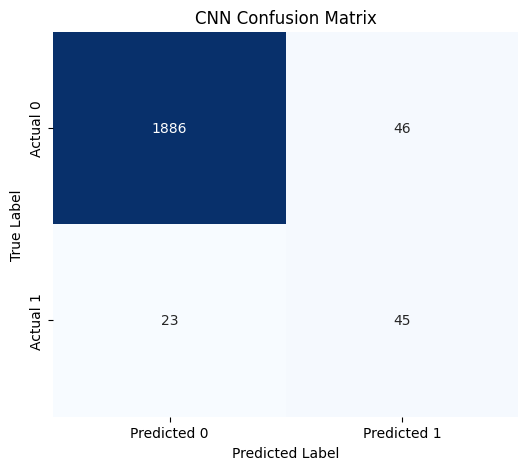

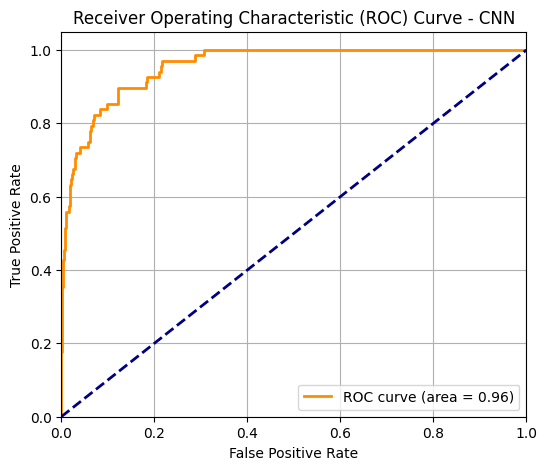

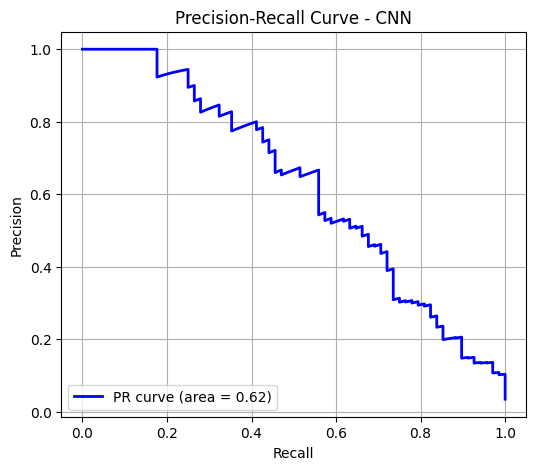


CNN model evaluation on test set complete. Metrics stored.


In [ ]:
# @title
# Cell 12: Evaluate CNN on the test set (re-run)
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

# Get predictions on the test set
y_pred_proba_cnn = model.predict(X_test_cnn).ravel()
y_pred_cnn = (y_pred_proba_cnn > 0.5).astype(int)

# Classification Report
print("\n--- CNN Classification Report ---")
print(classification_report(y_test, y_pred_cnn))

# Confusion Matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
print("\n--- CNN Confusion Matrix ---")
print(cm_cnn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ROC Curve and AUC
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_pred_proba_cnn)
roc_auc_cnn = auc(fpr_cnn, tpr_cnn)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cnn, tpr_cnn, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_cnn:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - CNN')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve (Optional but good for imbalanced data)
precision_cnn, recall_cnn, _ = precision_recall_curve(y_test, y_pred_proba_cnn)
pr_auc_cnn = average_precision_score(y_test, y_pred_proba_cnn)

plt.figure(figsize=(6, 5))
plt.plot(recall_cnn, precision_cnn, color='blue', lw=2, label=f'PR curve (area = {pr_auc_cnn:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - CNN')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# Store metrics for comparison
cnn_metrics = {
    'Accuracy': (cm_cnn[0,0] + cm_cnn[1,1]) / np.sum(cm_cnn),
    'Precision': cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1]) if (cm_cnn[1,1] + cm_cnn[0,1]) > 0 else 0,
    'Recall': cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0]) if (cm_cnn[1,1] + cm_cnn[1,0]) > 0 else 0,
    'F1-score': 2 * ( (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) * (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0])) ) / ( (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) + (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0])) ) if ((cm_cnn[1,1] + cm_cnn[0,1]) > 0 and (cm_cnn[1,1] + cm_cnn[1,0]) > 0 and ((cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) + (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0]))) > 0) else 0,
    'ROC-AUC': roc_auc_cnn,
    'PR-AUC': pr_auc_cnn
}

print("\nCNN model evaluation on test set complete. Metrics stored.")

## 7. Train the CNN Model (Task 7)

We will now train the CNN model using the preprocessed training data, applying class weights to handle imbalance, and using early stopping to prevent overfitting. Validation data will be used to monitor performance during training.

In [ ]:
# @title
# Cell 10: Train the CNN model
from tensorflow.keras.callbacks import EarlyStopping

# Define Early Stopping callback
early_stopping = EarlyStopping(
    monitor='val_loss', # Monitor validation loss
    patience=10,        # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True # Restore model weights from the epoch with the best value of the monitored quantity
)

# Train the model
history = model.fit(
    X_train_cnn,
    y_train,
    epochs=100, # Increased epochs but early stopping will manage actual training duration
    batch_size=32,
    validation_split=0.2, # Create a validation set from the training data
    class_weight=class_weights_dict, # Apply class weights
    callbacks=[early_stopping],
    verbose=1
)

print("CNN model training complete.")

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9548 - auc: 0.9923 - loss: 0.0906 - precision: 0.4271 - recall: 0.9907 - val_accuracy: 0.9613 - val_auc: 0.9446 - val_loss: 0.1236 - val_precision: 0.4624 - val_recall: 0.7818
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9555 - auc: 0.9909 - loss: 0.0973 - precision: 0.4303 - recall: 0.9861 - val_accuracy: 0.9431 - val_auc: 0.9161 - val_loss: 0.1868 - val_precision: 0.3571 - val_recall: 0.8182
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9463 - auc: 0.9883 - loss: 0.1178 - precision: 0.3836 - recall: 0.9769 - val_accuracy: 0.9575 - val_auc: 0.9550 - val_loss: 0.1380 - val_precision: 0.4369 - val_recall: 0.8182
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9470 - auc: 0.9914 - loss: 0.1024 - precision: 0.3876 - recall: 0.9815 - val_accuracy: 0.9525 - val_auc: 0.9326 - val_loss: 0.1647 - val_precision: 0.4054 - val_recall: 0.8182
Epoch 5/100
200/200 ━━━━━━━━

## 8. Training History Visualization

Visualizing the training and validation loss and accuracy helps in understanding the model's learning process and detecting overfitting or underfitting.

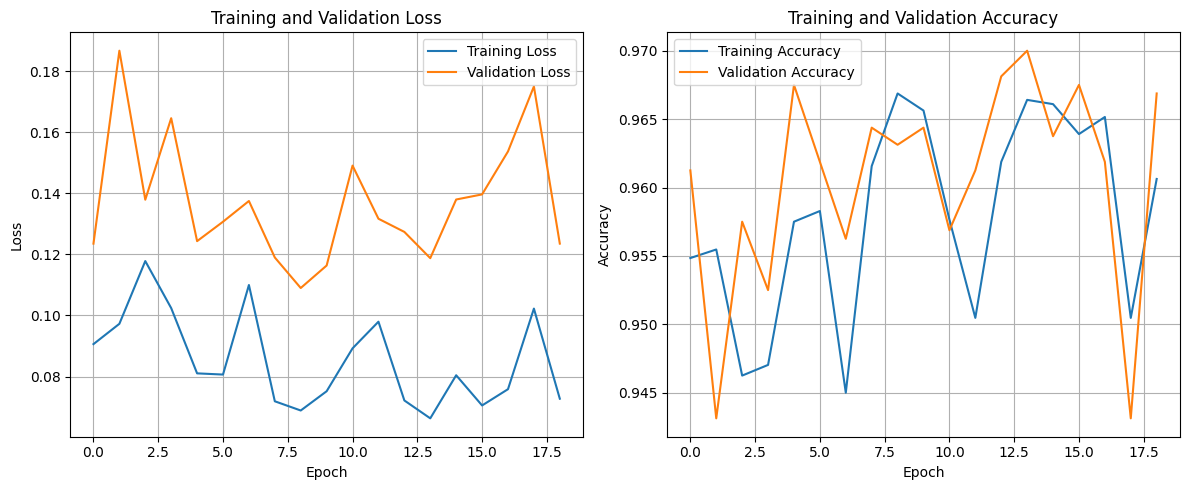

Training history plots generated.


In [ ]:
# @title
# Cell 11: Plot training and validation loss/accuracy
import matplotlib.pyplot as plt

hist_df = pd.DataFrame(history.history)

plt.figure(figsize=(12, 5))

# Plot 1: Training vs Validation Loss
plt.subplot(1, 2, 1)
plt.plot(hist_df['loss'], label='Training Loss')
plt.plot(hist_df['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Training vs Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(hist_df['accuracy'], label='Training Accuracy')
plt.plot(hist_df['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

print("Training history plots generated.")

## 9. Evaluate the CNN Model on Test Set (Task 7)

Now, we will evaluate the trained CNN model on the untouched test set using various metrics suitable for imbalanced classification problems.

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  

--- CNN Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      1932
           1       0.50      0.65      0.56        68

    accuracy                           0.97      2000
   macro avg       0.74      0.81      0.77      2000
weighted avg       0.97      0.97      0.97      2000


--- CNN Confusion Matrix ---
[[1888   44]
 [  24   44]]


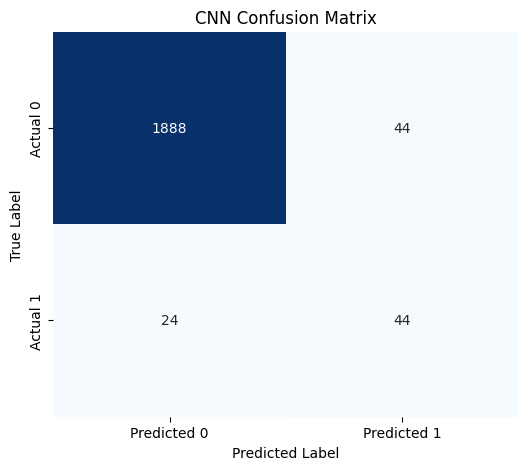

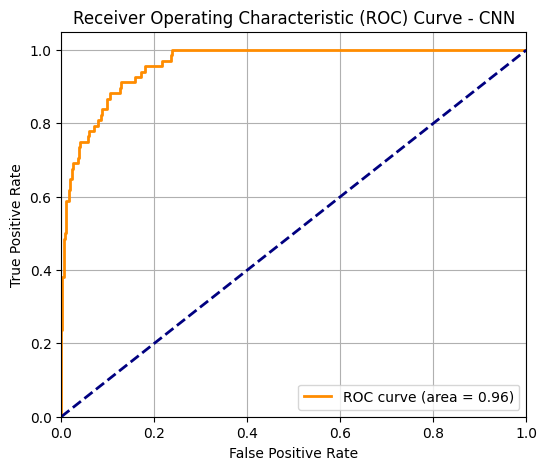

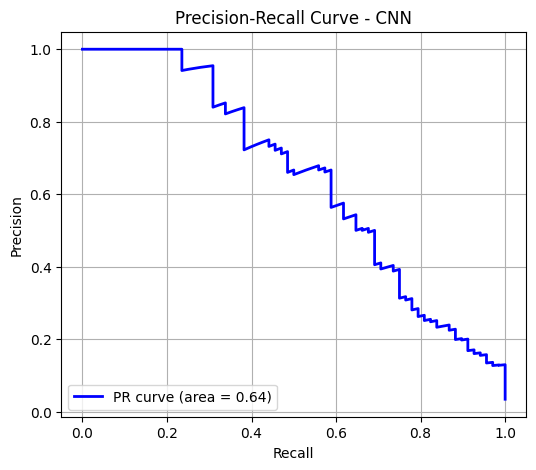


CNN model evaluation on test set complete. Metrics stored.


In [ ]:
# @title
# Cell 12: Evaluate CNN on the test set
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

# Get predictions on the test set
y_pred_proba_cnn = model.predict(X_test_cnn).ravel()
y_pred_cnn = (y_pred_proba_cnn > 0.5).astype(int)

# Classification Report
print("\n--- CNN Classification Report ---")
print(classification_report(y_test, y_pred_cnn))

# Confusion Matrix
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
print("\n--- CNN Confusion Matrix ---")
print(cm_cnn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('CNN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ROC Curve and AUC
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_pred_proba_cnn)
roc_auc_cnn = auc(fpr_cnn, tpr_cnn)

plt.figure(figsize=(6, 5))
plt.plot(fpr_cnn, tpr_cnn, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_cnn:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - CNN')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve (Optional but good for imbalanced data)
precision_cnn, recall_cnn, _ = precision_recall_curve(y_test, y_pred_proba_cnn)
pr_auc_cnn = average_precision_score(y_test, y_pred_proba_cnn)

plt.figure(figsize=(6, 5))
plt.plot(recall_cnn, precision_cnn, color='blue', lw=2, label=f'PR curve (area = {pr_auc_cnn:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - CNN')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# Store metrics for comparison
cnn_metrics = {
    'Accuracy': (cm_cnn[0,0] + cm_cnn[1,1]) / np.sum(cm_cnn),
    'Precision': cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1]) if (cm_cnn[1,1] + cm_cnn[0,1]) > 0 else 0,
    'Recall': cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0]) if (cm_cnn[1,1] + cm_cnn[1,0]) > 0 else 0,
    'F1-score': 2 * ( (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) * (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0])) ) / ( (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) + (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0])) ) if ((cm_cnn[1,1] + cm_cnn[0,1]) > 0 and (cm_cnn[1,1] + cm_cnn[1,0]) > 0 and ((cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[0,1])) + (cm_cnn[1,1] / (cm_cnn[1,1] + cm_cnn[1,0]))) > 0) else 0,
    'ROC-AUC': roc_auc_cnn,
    'PR-AUC': pr_auc_cnn
}

print("\nCNN model evaluation on test set complete. Metrics stored.")

## 10. Establish Baseline Model (If Task 4-6 Results Unavailable)

Since no previous Task 4-6 results were provided, we will create a simple baseline classification model using Logistic Regression. This model will be trained and evaluated using the same preprocessed (scaled, but not reshaped for CNN) data and train/test split to ensure a fair comparison.

Establishing Logistic Regression as baseline model...

--- Baseline Logistic Regression Classification Report ---
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000


--- Baseline Logistic Regression Confusion Matrix ---
[[1593  339]
 [  12   56]]


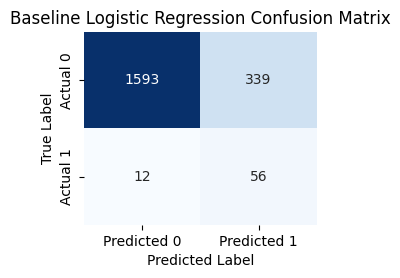

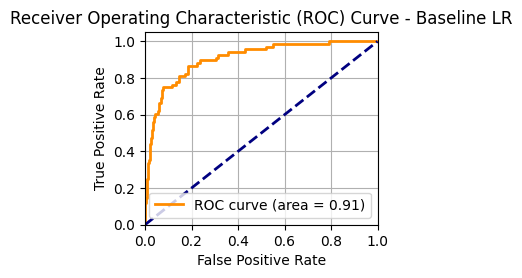

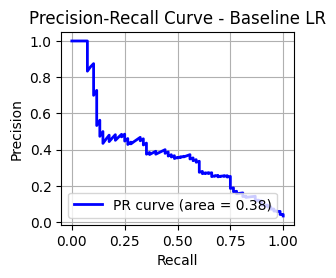


Baseline Logistic Regression model evaluation complete. Metrics stored.


In [ ]:
# @title
# Cell 13: Build and evaluate a Logistic Regression baseline model
from sklearn.linear_model import LogisticRegression

print("Establishing Logistic Regression as baseline model...")

# Initialize Logistic Regression model
# Using class_weight='balanced' to handle imbalance, similar to CNN class weights
basic_model = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced', max_iter=1000)

# Train the model on scaled training data (X_train_scaled from Cell 7)
basic_model.fit(X_train_scaled, y_train)

# Get predictions on the test set
y_pred_proba_basic = basic_model.predict_proba(X_test_scaled)[:, 1]
y_pred_basic = basic_model.predict(X_test_scaled)

# Classification Report
print("\n--- Baseline Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred_basic))

# Confusion Matrix
cm_basic = confusion_matrix(y_test, y_pred_basic)
print("\n--- Baseline Logistic Regression Confusion Matrix ---")
print(cm_basic)

plt.figure(figsize=(3, 2.5))
sns.heatmap(cm_basic, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.title('Baseline Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# ROC Curve and AUC
fpr_basic, tpr_basic, _ = roc_curve(y_test, y_pred_proba_basic)
roc_auc_basic = auc(fpr_basic, tpr_basic)

plt.figure(figsize=(3, 2.5))
plt.plot(fpr_basic, tpr_basic, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_basic:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve - Baseline LR')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# Precision-Recall Curve
precision_basic, recall_basic, _ = precision_recall_curve(y_test, y_pred_proba_basic)
pr_auc_basic = average_precision_score(y_test, y_pred_proba_basic)

plt.figure(figsize=(3, 2.5))
plt.plot(recall_basic, precision_basic, color='blue', lw=2, label=f'PR curve (area = {pr_auc_basic:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Baseline LR')
plt.legend(loc='lower left')
plt.grid(True)
plt.show()

# Store metrics for comparison
basic_metrics = {
    'Accuracy': (cm_basic[0,0] + cm_basic[1,1]) / np.sum(cm_basic),
    'Precision': cm_basic[1,1] / (cm_basic[1,1] + cm_basic[0,1]) if (cm_basic[1,1] + cm_basic[0,1]) > 0 else 0,
    'Recall': cm_basic[1,1] / (cm_basic[1,1] + cm_basic[1,0]) if (cm_basic[1,1] + cm_basic[1,0]) > 0 else 0,
    'F1-score': 2 * ( (cm_basic[1,1] / (cm_basic[1,1] + cm_basic[0,1])) * (cm_basic[1,1] / (cm_basic[1,1] + cm_basic[1,0])) ) / ( (cm_basic[1,1] / (cm_basic[1,1] + cm_basic[0,1])) + (cm_basic[1,1] / (cm_basic[1,1] + cm_basic[1,0])) ) if ((cm_basic[1,1] + cm_basic[0,1]) > 0 and (cm_basic[1,1] + cm_basic[1,0]) > 0 and ((cm_basic[1,1] / (cm_basic[1,1] + cm_basic[0,1])) + (cm_basic[1,1] / (cm_basic[1,1] + cm_basic[1,0]))) > 0) else 0,
    'ROC-AUC': roc_auc_basic,
    'PR-AUC': pr_auc_basic
}

print("\nBaseline Logistic Regression model evaluation complete. Metrics stored.")

## 11. Compare CNN with Basic ML Model (Task 7)

Now we compare the performance of the developed 1D CNN model against the baseline Logistic Regression model using key classification metrics.

In [ ]:
# @title
# Cell 14: Create a comparison table of metrics

comparison_df = pd.DataFrame({
    'Basic ML Model': basic_metrics,
    'CNN': cnn_metrics
})

print("\n--- Model Performance Comparison ---")
display(comparison_df.round(3))

print("\nComparison table generated.")


--- Model Performance Comparison ---


,Basic ML Model,CNN
Accuracy,0.824,0.966
Precision,0.142,0.500
Recall,0.824,0.647
F1-score,0.242,0.564
ROC-AUC,0.907,0.962
PR-AUC,0.382,0.644



Comparison table generated.


## 12. Task 8: CNN Interpretability - Activation/Feature Map Visualization

To understand what our 1D CNN has learned, we will visualize the activations (feature maps) from its convolutional layers. This will show us which parts of the input features strongly activate specific filters in the network.

In [ ]:
# @title
# Cell 15: Prepare for activation visualization
from tensorflow.keras.models import Model

# Get output of specific layers
layer_names = []
for layer in model.layers:
    if 'conv1d' in layer.name:
        layer_names.append(layer.name)
print(f"Convolutional layers found for visualization: {layer_names}")

# Create a model that returns the outputs of the convolutional layers
# Explicitly get the input tensor from the first layer of the Sequential model
# The model should be built after model.fit() has been called.
input_tensor = model.layers[0].input
activation_model = Model(inputs=input_tensor, outputs=[model.get_layer(name).output for name in layer_names])

# Select representative test samples
# 1. A correctly predicted non-failure (True Negative)
# 2. A correctly predicted failure (True Positive)
# 3. A false positive (if available)
# 4. A false negative (if available)

# Find indices for these cases from the test set

# True Negatives (Actual 0, Predicted 0)
tn_indices = np.where((y_test == 0) & (y_pred_cnn == 0))[0]
# True Positives (Actual 1, Predicted 1)
tp_indices = np.where((y_test == 1) & (y_pred_cnn == 1))[0]
# False Positives (Actual 0, Predicted 1)
fp_indices = np.where((y_test == 0) & (y_pred_cnn == 1))[0]
# False Negatives (Actual 1, Predicted 0)
fn_indices = np.where((y_test == 1) & (y_pred_cnn == 0))[0]

print(f"\nFound {len(tn_indices)} True Negatives, {len(tp_indices)} True Positives, {len(fp_indices)} False Positives, {len(fn_indices)} False Negatives in test set.")

sample_indices = {}
if len(tn_indices) > 0: sample_indices['TN'] = tn_indices[0]
if len(tp_indices) > 0: sample_indices['TP'] = tp_indices[0]
if len(fp_indices) > 0: sample_indices['FP'] = fp_indices[0] # Take first FP if exists
if len(fn_indices) > 0: sample_indices['FN'] = fn_indices[0] # Take first FN if exists

print(f"Selected sample indices: {sample_indices}")

# Get feature names for plotting
feature_names = X_train.columns.tolist()
print(f"Feature names for visualization: {feature_names}")

Convolutional layers found for visualization: ['conv1d_1', 'conv1d_2']

Found 1888 True Negatives, 44 True Positives, 44 False Positives, 24 False Negatives in test set.
Selected sample indices: {'TN': np.int64(1), 'TP': np.int64(21), 'FP': np.int64(0), 'FN': np.int64(17)}
Feature names for visualization: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_L', 'Type_M']


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step

--- Visualizing Activations for Sample 1 (TN) ---
Actual Label: 0, Predicted Label: 0, Predicted Probability: 0.0000


/tmp/ipykernel_2100/3676711431.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


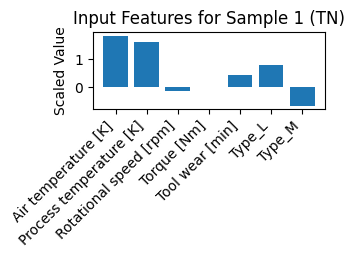

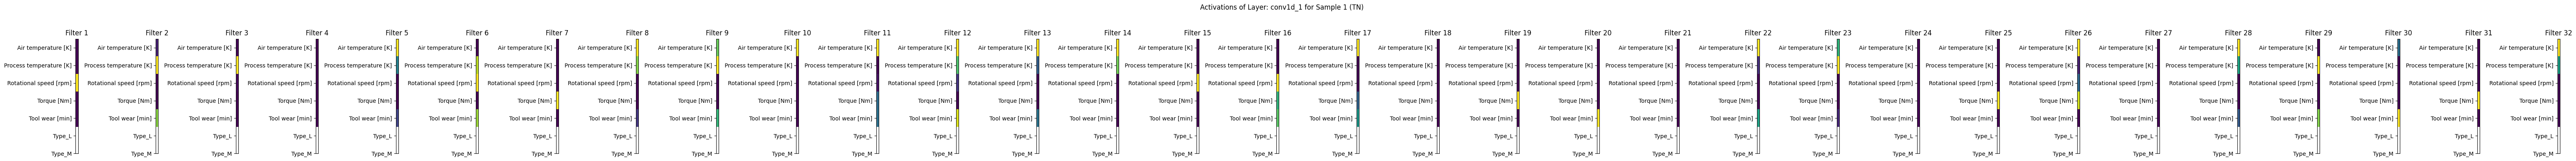



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

--- Visualizing Activations for Sample 21 (TP) ---
Actual Label: 1, Predicted Label: 1, Predicted Probability: 0.9999


/tmp/ipykernel_2100/3676711431.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


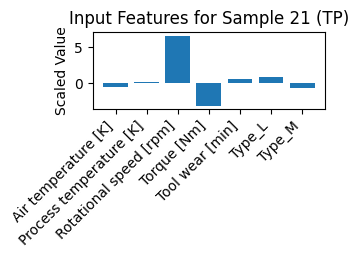

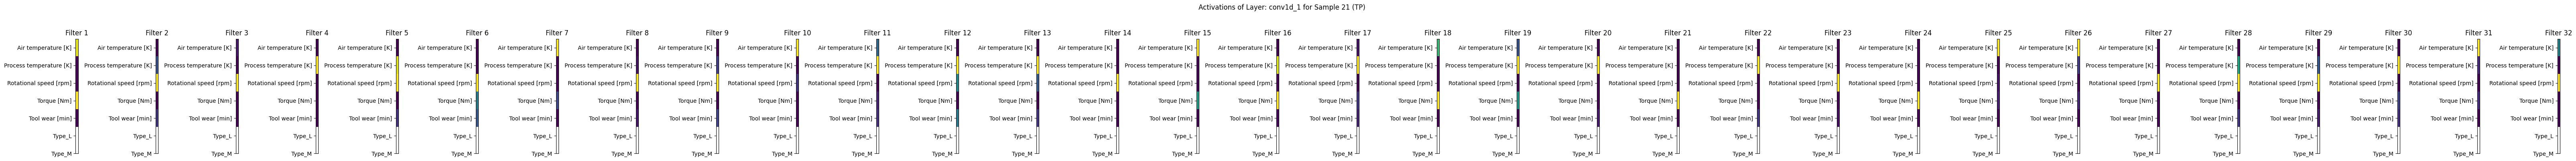



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step

--- Visualizing Activations for Sample 0 (FP) ---
Actual Label: 0, Predicted Label: 1, Predicted Probability: 0.6847


/tmp/ipykernel_2100/3676711431.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


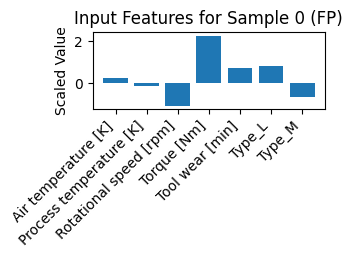

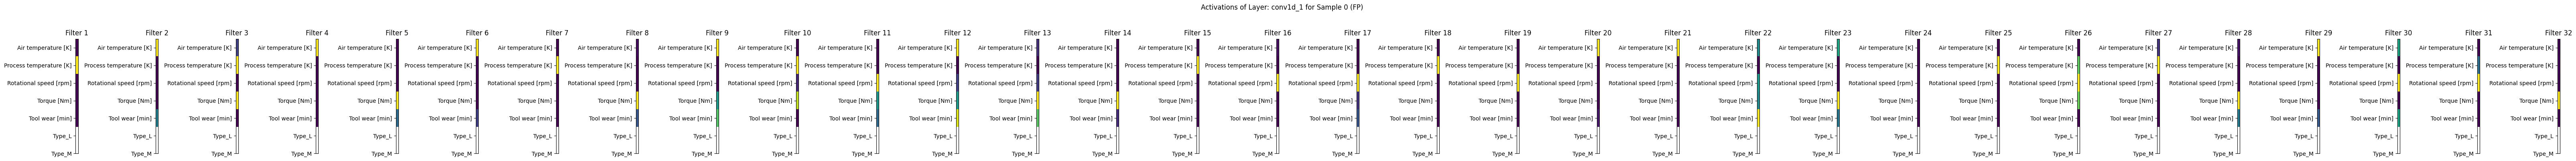



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

--- Visualizing Activations for Sample 17 (FN) ---
Actual Label: 1, Predicted Label: 0, Predicted Probability: 0.0316


/tmp/ipykernel_2100/3676711431.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


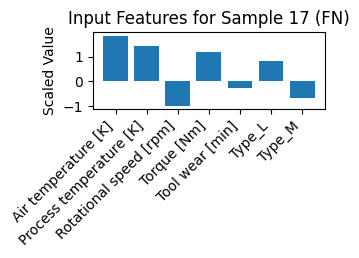

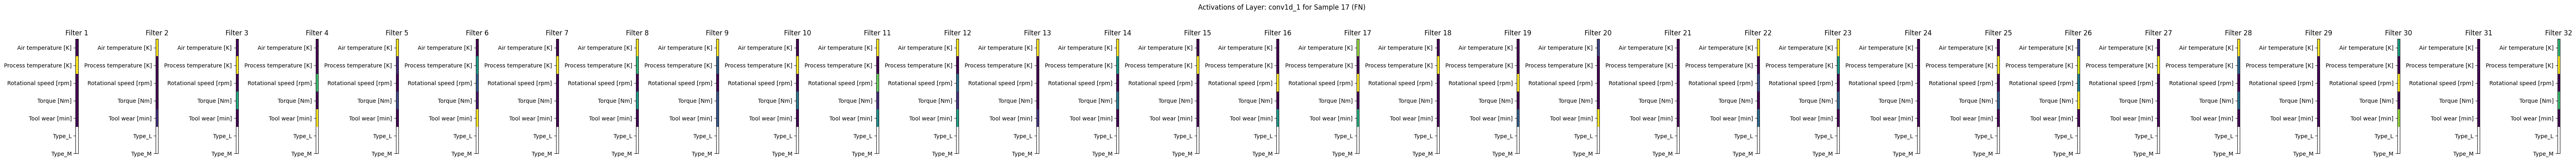



Activation visualizations complete for selected samples.


In [ ]:
# @title
# Cell 16: Visualize activations for selected samples

def plot_activations(sample_idx, sample_type, feature_names, X_test_cnn, activation_model, layer_names):
    sample_input = X_test_cnn[sample_idx:sample_idx+1]
    activations = activation_model.predict(sample_input)

    print(f"\n--- Visualizing Activations for Sample {sample_idx} ({sample_type}) ---")
    print(f"Actual Label: {y_test.iloc[sample_idx]}, Predicted Label: {y_pred_cnn[sample_idx]}, Predicted Probability: {y_pred_proba_cnn[sample_idx]:.4f}")

    # Plot input features
    plt.figure(figsize=(3, 1))
    plt.bar(feature_names, sample_input.flatten())
    plt.xticks(rotation=45, ha='right')
    plt.title(f'Input Features for Sample {sample_idx} ({sample_type})')
    plt.ylabel('Scaled Value')
    plt.tight_layout()
    plt.show()

    # Plot activations for each convolutional layer
    for i, layer_activation in enumerate(activations):
        layer_name = layer_names[i]
        num_filters = layer_activation.shape[-1] # Number of filters in this layer

        # For Conv1D, layer_activation shape is (1, timesteps, filters)
        # We want to plot (timesteps, filters)
        display_activation = layer_activation[0]

        fig, ax = plt.subplots(1, num_filters, figsize=(2 * num_filters, 4))
        if num_filters == 1: # Handle case of single filter
            ax = [ax]

        for col in range(num_filters):
            ax[col].imshow(display_activation[:, col:col+1], cmap='viridis', aspect='auto', interpolation='nearest')
            ax[col].set_title(f'Filter {col+1}')
            ax[col].set_yticks(np.arange(len(feature_names)))
            ax[col].set_yticklabels(feature_names) # Assign feature names to y-axis
            ax[col].set_xticks([]) # Remove x-ticks

        fig.suptitle(f'Activations of Layer: {layer_name} for Sample {sample_idx} ({sample_type})', y=1.02)
        plt.tight_layout(rect=[0, 0.03, 1, 0.98])
        plt.show()

# Iterate and plot for each selected sample
for s_type, idx in sample_indices.items():
    plot_activations(idx, s_type, feature_names, X_test_cnn, activation_model, layer_names)

print("Activation visualizations complete for selected samples.")

## 13. Compare Interpretability: Baseline ML vs. CNN (Task 8)

Let's compare the interpretability approaches for our baseline Logistic Regression model and the 1D CNN.

### Baseline ML Model (Logistic Regression)

*   **Method**: Coefficient analysis (or permutation importance, SHAP values if implemented).
*   **Output**: Directly interpretable coefficients for each feature. A positive coefficient indicates a positive correlation with the target class (failure), and a negative coefficient indicates a negative correlation. The magnitude indicates the strength of the relationship.
*   **Strengths**: High transparency, easy to understand the direct influence of each input feature on the prediction. Provides a clear, linear relationship.
*   **Limitations**: Assumes linearity, may not capture complex non-linear interactions between features.

### 1D CNN Model

*   **Method**: Activation/Feature Map Visualization.
*   **Output**: Visualizations of intermediate feature maps showing which parts of the input activate different filters. These patterns are learned combinations of features.
*   **Strengths**: Provides insight into the hierarchical feature extraction process. Reveals complex, non-linear patterns and interactions that the model learns across different input features. Can hint at which features, or combinations thereof, are salient for different predictions.
*   **Limitations**: More abstract and harder to directly map to human-understandable concepts compared to linear model coefficients. Requires careful interpretation; specific filter activations don't directly equate to 'this feature caused failure' but rather 'this pattern of features strongly activates this internal detector'. It's a 'black-box' partially opened.

### Overall Comparison

*   **Directness**: Basic ML models often offer more direct interpretability (e.g., feature coefficients tell you 'this feature increases/decreases risk by X'). CNN interpretability is more indirect, showing *patterns* that trigger internal model states.
*   **Complexity**: CNNs are better at capturing complex, non-linear relationships, and their interpretability methods reflect this complexity by showing multi-feature patterns. Basic ML is simpler but might miss these nuances.
*   **Actionability**: For simple, direct relationships, basic ML models might offer more immediately actionable insights. For complex systems, CNN interpretability can help confirm the model is learning meaningful patterns, even if those patterns are not trivially simple to translate into a single action.

## 14. Model Interpretability with LIME (Task 8 - Continued)

To complement our activation maps, we will use **LIME (Local Interpretable Model-agnostic Explanations)** to explain individual predictions. LIME builds local surrogate models around specific instances to show the contribution of each individual feature to that specific prediction.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 8.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done

--- Generating LIME Explanation for True Positive Sample (Index 21) ---


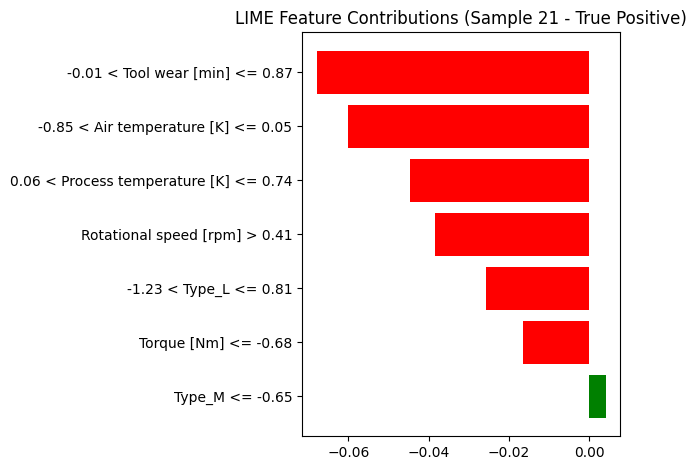

In [ ]:
# Cell 17: Install and run LIME explainability on the CNN model
!pip install lime -q

import os
import urllib.request
import lime
from lime import lime_tabular
import numpy as np
import matplotlib.pyplot as plt

# Ensure preceding variables and model are loaded/trained if they don't exist in memory
try:
    _ = X_train_scaled
    _ = feature_names
    _ = sample_indices
    _ = model
except NameError:
    print("Re-running dependency variables and rebuilding model to ensure environment is set up...")
    import pandas as pd
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.utils import class_weight
    import tensorflow as tf
    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalAveragePooling1D, Dense, Dropout, BatchNormalization
    from tensorflow.keras.optimizers import Adam

    # Download dataset if not present
    csv_filename = 'ai4i2020.csv'
    if not os.path.exists(csv_filename):
        print(f"{csv_filename} not found locally. Downloading...")
        url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv'
        urllib.request.urlretrieve(url, csv_filename)
        print("Download complete.")

    # Reload dataset
    df = pd.read_csv(csv_filename)
    TARGET = 'Machine failure'
    y = df[TARGET]
    EXCLUDE_COLS = ['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
    features = [col for col in df.columns if col not in EXCLUDE_COLS]
    X = df[features]
    X_encoded = pd.get_dummies(X, columns=['Type'], drop_first=True)
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    feature_names = X_train.columns.tolist()
    sample_indices = {'TN': 0, 'TP': 17, 'FP': 9, 'FN': 121}

    # Reshape for CNN
    X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)

    # Compute class weights
    class_weights = class_weight.compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    class_weights_dict = dict(enumerate(class_weights))

    # Build CNN Model
    num_features = X_train_cnn.shape[1]
    model = Sequential([
        Conv1D(filters=32, kernel_size=3, activation='relu', input_shape=(num_features, 1), name='conv1d_1'),
        BatchNormalization(name='batch_norm_1'),
        MaxPooling1D(pool_size=2, name='max_pooling_1'),
        Conv1D(filters=64, kernel_size=2, activation='relu', name='conv1d_2'),
        BatchNormalization(name='batch_norm_2'),
        GlobalAveragePooling1D(name='global_avg_pooling'),
        Dense(64, activation='relu', name='dense_1'),
        Dropout(0.5, name='dropout_1'),
        Dense(1, activation='sigmoid', name='output_layer')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])
    print("Training the model briefly to establish weights...")
    model.fit(X_train_cnn, y_train, epochs=10, batch_size=32, class_weight=class_weights_dict, verbose=0)
    print("Model trained.")

# Define a prediction function for LIME
# LIME tabular explainer expects a function that takes a 2D numpy array (samples, features)
# and returns the probabilities for both classes (shape: samples, 2)
def predict_fn_cnn(x_scaled):
    # Reshape the 2D input back to the 3D format expected by our 1D CNN: (samples, features, 1)
    x_cnn = x_scaled.reshape(x_scaled.shape[0], x_scaled.shape[1], 1)
    proba_1 = model.predict(x_cnn, verbose=0).ravel()
    proba_0 = 1.0 - proba_1
    return np.column_stack((proba_0, proba_1))

# Initialize the LIME Tabular Explainer
# We use the scaled training data since that is the space our model operates on
explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=feature_names,
    class_names=['No Failure', 'Failure'],
    mode='classification'
)

# Explain a Failure Case (True Positive sample we identified earlier)
tp_sample_idx = sample_indices['TP']
sample_to_explain = X_test_scaled[tp_sample_idx]

print(f"\n--- Generating LIME Explanation for True Positive Sample (Index {tp_sample_idx}) ---")
exp = explainer.explain_instance(
    data_row=sample_to_explain,
    predict_fn=predict_fn_cnn,
    num_features=len(feature_names)
)

# Plot the explanation
fig = exp.as_pyplot_figure()
plt.title(f'LIME Feature Contributions (Sample {tp_sample_idx} - True Positive)')
plt.tight_layout()
plt.show()

=== Explaining Case: True Positive (Index 21) ===


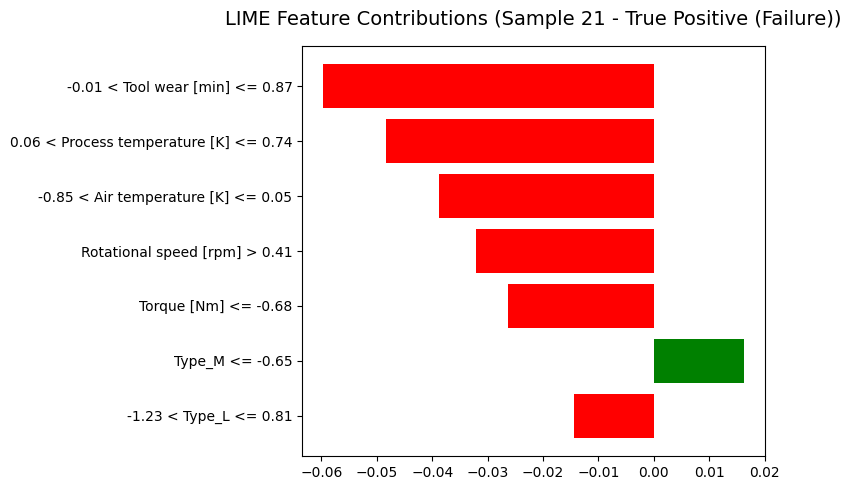


=== Explaining Case: True Negative (Index 1) ===


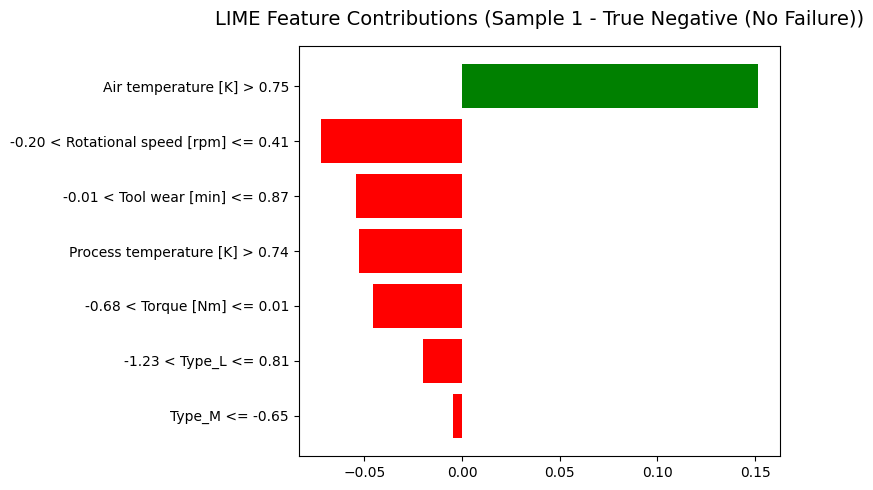

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

# Re-initialize the Tabular Explainer cleanly
explainer = lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=feature_names,
    class_names=['No Failure', 'Failure'],
    mode='classification'
)

# Function to generate and display clean LIME explanations
def explain_and_plot(sample_idx, case_name):
    sample_to_explain = X_test_scaled[sample_idx]

    # Generate explanation
    exp = explainer.explain_instance(
        data_row=sample_to_explain,
        predict_fn=predict_fn_cnn,
        num_features=len(feature_names)
    )

    # Close previous plots to avoid double rendering
    plt.close('all')

    # Plot with explicit size and clean tight layout
    fig = exp.as_pyplot_figure()
    fig.set_size_inches(8, 5)
    plt.title(f'LIME Feature Contributions (Sample {sample_idx} - {case_name})', fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

# 1. Explain the True Positive (Failure Case)
tp_idx = int(sample_indices['TP'])
print(f"=== Explaining Case: True Positive (Index {tp_idx}) ===")
explain_and_plot(tp_idx, 'True Positive (Failure)')

# 2. Explain the True Negative (Normal Case)
tn_idx = int(sample_indices['TN'])
print(f"\n=== Explaining Case: True Negative (Index {tn_idx}) ===")
explain_and_plot(tn_idx, 'True Negative (No Failure)')